# OpenAlex Researcher Collaboration Network

This project uses OpenAlex publication data to build a small researcher collaboration network.

We will begin with one researcher, retrieve some of their recent publications, identify coauthors, and then continue outward through the coauthor network.

The resulting graph represents researchers and coauthorship relationships:

- each node is an OpenAlex author
- an edge connects two authors who appear together on a publication
- an edge weight increases when the same two authors appear together on more than one retrieved publication

The goal is to show how research information retrieved from an API can be represented as a network. This is not intended to be a complete introduction to network analysis.


## 1. Setup

We will use:

- `requests` to query OpenAlex
- `networkx` to construct the network
- `matplotlib` to visualize the graph
- `deque` to keep track of researchers whose publications we still need to retrieve
- `combinations` to create pairs of coauthors from each publication

OpenAlex can be queried without an API key for a small teaching example like this one.


In [1]:
import requests
import json
import networkx as nx
import matplotlib.pyplot as plt
import time

from collections import deque
from itertools import combinations

OPENALEX_BASE = "https://api.openalex.org"


## 2. Choose a Researcher and Network Size

We will begin with a researcher name rather than an OpenAlex ID.

The example uses Jennifer Doudna. You can replace this with another researcher later.

Two additional settings keep the example manageable:

- `MAX_AUTHORS` limits the total number of researchers in the graph
- `MAX_WORKS_PER_AUTHOR` limits how many publications we retrieve for each researcher we search

Increasing either value can produce a larger network and more API requests.


In [2]:
SEED_AUTHOR = "Jennifer Doudna"

MAX_AUTHORS = 20
MAX_WORKS_PER_AUTHOR = 5
REQUEST_DELAY = 0.1


## 3. Helper Functions

The following functions handle three recurring tasks:

1. make a request to OpenAlex
2. find an OpenAlex author from a researcher name
3. retrieve recent works associated with an author

A final helper extracts the authors from an OpenAlex work record.


In [3]:
def openalex_get(path, params=None):
    params = dict(params or {})

    response = requests.get(
        f"{OPENALEX_BASE}/{path}",
        params=params,
        timeout=30
    )

    time.sleep(REQUEST_DELAY)

    if response.status_code == 429:
        print("Rate limit reached - waiting 5 seconds...")
        time.sleep(5)
        response = requests.get(
            f"{OPENALEX_BASE}/{path}",
            params=params,
            timeout=30
        )

    response.raise_for_status()
    return response.json()


def find_author(author_name):
    data = openalex_get(
        "authors",
        {
            "search": author_name,
            "per-page": 10
        }
    )

    results = data.get("results", [])

    if not results:
        return None

    exact = [
        author
        for author in results
        if author.get("display_name", "").casefold()
        == author_name.casefold()
    ]

    return exact[0] if exact else results[0]


def get_works(author_id):
    short_id = author_id.rsplit("/", 1)[-1]

    data = openalex_get(
        "works",
        {
            "filter": f"author.id:{short_id}",
            "sort": "publication_date:desc",
            "per-page": min(MAX_WORKS_PER_AUTHOR, 100)
        }
    )

    return data.get("results", [])[:MAX_WORKS_PER_AUTHOR]


def work_authors(work):
    authors = []
    seen = set()

    for authorship in work.get("authorships", []):
        author = authorship.get("author") or {}

        author_id = author.get("id")
        name = author.get("display_name")

        if author_id and author_id not in seen:
            authors.append(
                (
                    author_id,
                    name or author_id.rsplit("/", 1)[-1]
                )
            )
            seen.add(author_id)

    return authors


## 4. Find the Starting Researcher

First, use OpenAlex to resolve the researcher name to an author record.

For a real research project, researcher identification can require additional validation. For this teaching example, the function uses an exact display-name match when possible and otherwise takes the first OpenAlex search result.


In [4]:
seed = find_author(SEED_AUTHOR)

if seed is None:
    raise ValueError(
        f"No OpenAlex author found for {SEED_AUTHOR!r}"
    )

seed


{'id': 'https://openalex.org/A5067184382',
 'orcid': 'https://orcid.org/0000-0001-9161-999X',
 'observed_orcids': ['https://orcid.org/0000-0001-9161-999X'],
 'display_name': 'Jennifer A. Doudna',
 'raw_author_names': ['Doudna Ja',
  'Doudna, J.A.',
  'Doudna, Jennifer',
  'Doudna, Jennifer A',
  'Doudna, Jennifer A.',
  'Doudna, Jennifer A. 1964-',
  'Doudna, Jennifer A.; Banfield, Jillian; Burstein, David; Harrington, Lucas Benjamin; Strutt, Steven C.',
  'Doudna, Jennifer A.; Burstein, David; Chen, Janice S.; Harrington, Lucas Benjamin; Paez-Espino, David; Banfield, Jillian F.',
  'Doudna, Jennifer A.; Qi, Lei S.; Haurwitz, Rachel E.; Arkin, Adam P.',
  'Doudna. Jennifer A',
  'Dr. Jennifer Doudna,',
  'J A Doudna',
  'J. A. DOUDNA',
  'J. A. Doudna',
  'J. Doudna',
  'J.A. DOUDNA',
  'J.A. Doudna',
  'JENNIFER A. DOUDNA',
  'Jennifer A Doudna',
  'Jennifer A. Doudna',
  'Jennifer Doudna',
  'Jennifer\xa0A Doudna',
  'Jennifer\xa0A. Doudna',
  'Jennifer\u2005A. Doudna'],
 'full_name'

In [5]:
print("Researcher:", seed["display_name"])
print("OpenAlex ID:", seed["id"])
print("Works:", seed.get("works_count"))


Researcher: Jennifer A. Doudna
OpenAlex ID: https://openalex.org/A5067184382
Works: 704


## 5. Build the Coauthor Network

We will now expand outward from the starting researcher.

The process uses a breadth-first search:

1. Put the starting researcher in a queue.
2. Retrieve some of that researcher's publications.
3. Add coauthors from those publications to the graph.
4. Put newly discovered coauthors into the queue.
5. Continue retrieving publications for researchers in the queue.
6. Stop when the graph reaches `MAX_AUTHORS`.

For every publication we process, all authors who are already included in our graph are connected to one another.

This means the graph can contain relationships among coauthors, not only relationships between the starting researcher and everyone else.


In [6]:
seed_id = seed["id"]

G = nx.Graph()
G.add_node(
    seed_id,
    label=seed["display_name"]
)

frontier = deque([seed_id])
searched = set()
processed_works = set()


The `frontier` contains researchers whose publications still need to be retrieved.

The `searched` set prevents us from searching the same researcher repeatedly.

The `processed_works` set prevents the same publication from being added to the network more than once.


In [7]:
while frontier and G.number_of_nodes() < MAX_AUTHORS:

    author_id = frontier.popleft()

    if author_id in searched:
        continue

    author_name = G.nodes[author_id].get(
        "label",
        author_id
    )

    print(
        f"Searching {author_name} "
        f"({G.number_of_nodes()} authors so far)"
    )

    searched.add(author_id)

    for work in get_works(author_id):

        work_id = work.get("id")

        if not work_id or work_id in processed_works:
            continue

        processed_works.add(work_id)

        authors = work_authors(work)

        author_ids = {
            author_id
            for author_id, _ in authors
        }

        if author_id not in author_ids:
            continue

        # Add newly discovered coauthors to the graph.
        for coauthor_id, coauthor_name in authors:

            if (
                coauthor_id != author_id
                and coauthor_id not in G
                and G.number_of_nodes() < MAX_AUTHORS
            ):
                G.add_node(
                    coauthor_id,
                    label=coauthor_name
                )

                if coauthor_id not in searched:
                    frontier.append(coauthor_id)

        # Keep authors from this publication who are
        # currently included in our bounded graph.
        graph_authors = [
            (author_id, name)
            for author_id, name in authors
            if author_id in G
        ]

        # Every pair of authors on the publication
        # represents a coauthorship relationship.
        for (author_a, _), (author_b, _) in combinations(
            graph_authors,
            2
        ):

            if G.has_edge(author_a, author_b):
                G[author_a][author_b]["weight"] += 1
            else:
                G.add_edge(
                    author_a,
                    author_b,
                    weight=1
                )


Searching Jennifer A. Doudna (1 authors so far)


## 6. Inspect the Network

Before visualizing the graph, look at some basic information about what we constructed.


In [8]:
print("Finished!")
print("Authors:", G.number_of_nodes())
print(
    "Coauthor relationships:",
    G.number_of_edges()
)
print("Authors searched:", len(searched))
print("Works processed:", len(processed_works))
print(
    "Isolated authors:",
    len(list(nx.isolates(G)))
)

if G.number_of_nodes():
    print("Connected:", nx.is_connected(G))


Finished!
Authors: 20
Coauthor relationships: 142
Authors searched: 1
Works processed: 5
Isolated authors: 0
Connected: True


The graph is intentionally bounded.

`MAX_AUTHORS = 20` does not mean that the researcher has only 20 collaborators. It means that we chose to stop expanding the network after adding 20 researchers.

Likewise, `MAX_WORKS_PER_AUTHOR = 5` means that the network is based on only a small sample of recent publications for each researcher searched.

These choices make the example manageable, but they also affect the network we produce.


## 7. Look at Some Nodes and Edges

NetworkX stores information about both nodes and edges.

The nodes contain OpenAlex author IDs and researcher names.


In [9]:
list(G.nodes(data=True))[:5]


[('https://openalex.org/A5067184382', {'label': 'Jennifer A. Doudna'}),
 ('https://openalex.org/A5069836267', {'label': 'Santiago C. Lopez'}),
 ('https://openalex.org/A5158986689', {'label': 'Ella Brie T. Mayor'}),
 ('https://openalex.org/A5093273003', {'label': 'Kenneth J. Loi'}),
 ('https://openalex.org/A5064190476', {'label': 'Emily G. Armbruster'})]

The edges represent coauthorship relationships.

The `weight` records how many processed publications contained that pair of researchers.


In [10]:
list(G.edges(data=True))[:10]


[('https://openalex.org/A5067184382',
  'https://openalex.org/A5069836267',
  {'weight': 3}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5158986689',
  {'weight': 1}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5093273003',
  {'weight': 4}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5064190476',
  {'weight': 1}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5159000079',
  {'weight': 1}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5093130385',
  {'weight': 4}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5026191557',
  {'weight': 2}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5158036833',
  {'weight': 1}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5071269401',
  {'weight': 1}),
 ('https://openalex.org/A5067184382',
  'https://openalex.org/A5144232709',
  {'weight': 1})]

## 8. Visualize the Network

NetworkX provides several graph layout algorithms.

Here we use a spring layout. Nodes that are more strongly connected tend to be drawn closer together, although the layout should not be interpreted as a literal physical distance.

The labels stored on the nodes allow us to display researcher names rather than OpenAlex IDs.


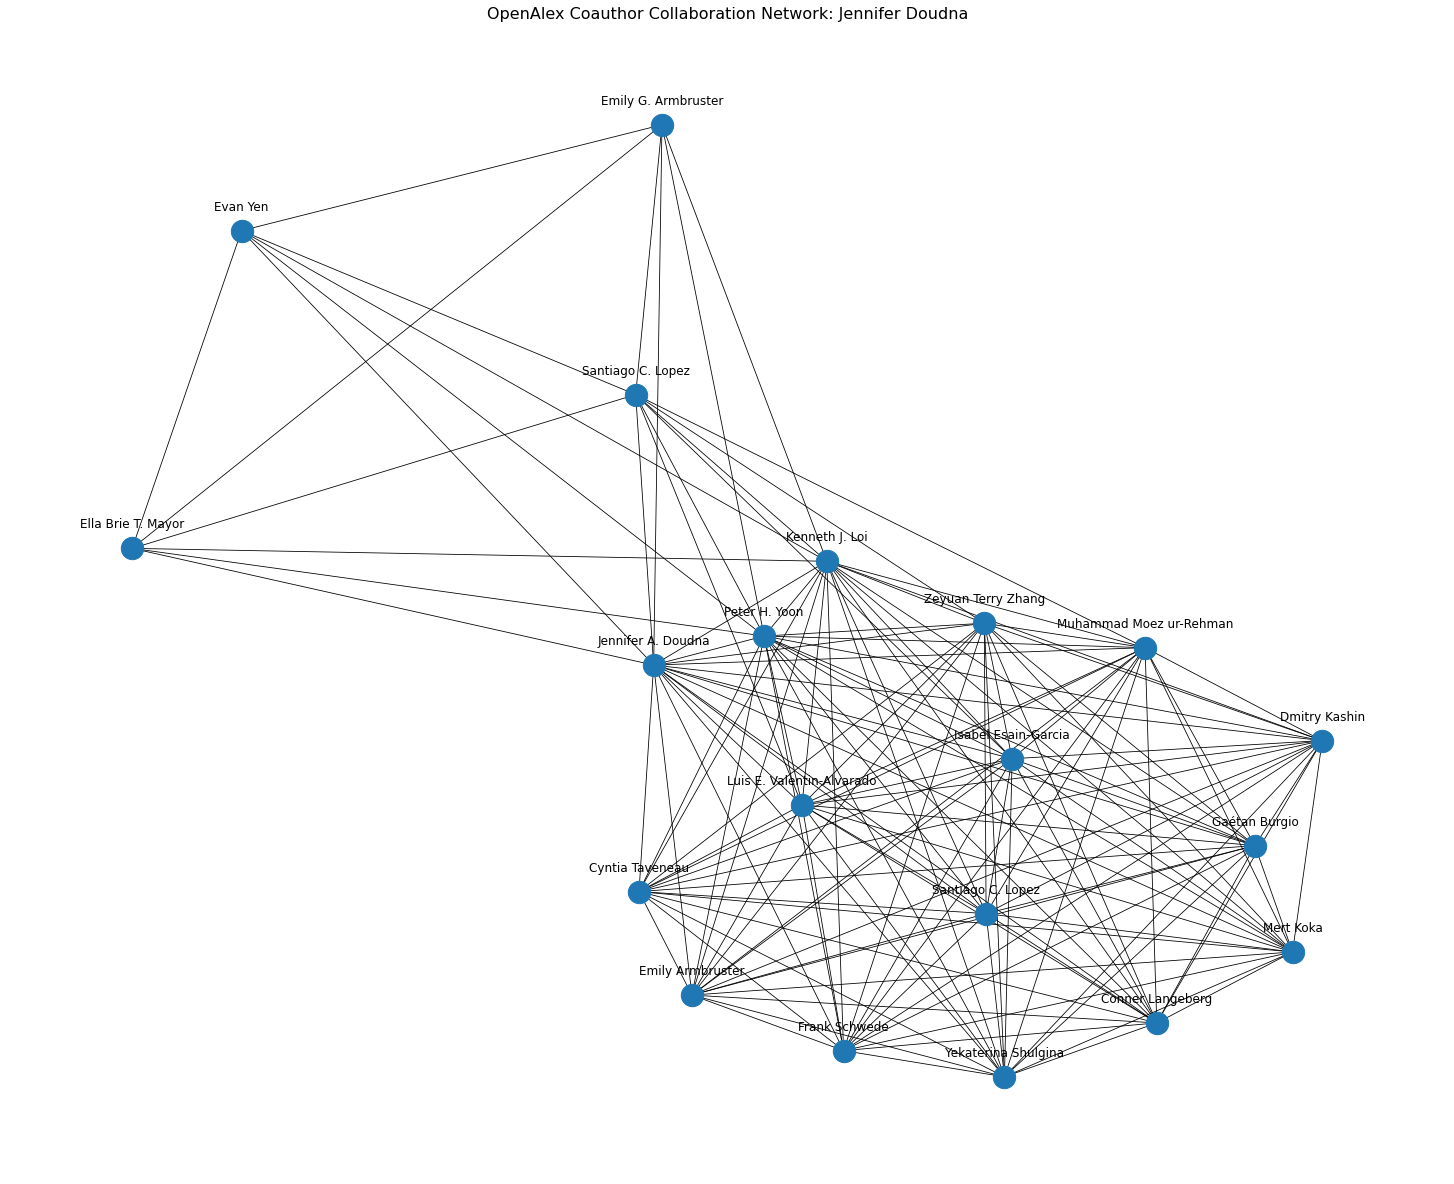

In [11]:
plt.figure(figsize=(20, 16))

pos = nx.spring_layout(
    G,
    seed=42,
    k=2.5,
    iterations=100
)

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=500,
    width=0.8
)

label_pos = {
    node: (x, y + 0.04)
    for node, (x, y) in pos.items()
}

labels = {
    node: data.get("label", node)
    for node, data in G.nodes(data=True)
}

nx.draw_networkx_labels(
    G,
    label_pos,
    labels=labels,
    font_size=12
)

plt.title(
    f"OpenAlex Coauthor Collaboration Network: {SEED_AUTHOR}",
    fontsize=16
)

plt.axis("off")
plt.show()


## 9. Interpret the Network

The graph represents a small sample of collaboration relationships discovered by expanding outward from one researcher.

Some questions to consider:

- Which researchers appear highly connected?
- Which groups of researchers appear close together?
- Which relationships have larger edge weights?
- How much of the graph comes from the starting researcher's publications?
- How much comes from publications retrieved for newly discovered coauthors?
- How might the graph change if we increased `MAX_AUTHORS`?
- How might it change if we retrieved more works for each researcher?
- How might limiting publications by date change the network?

The graph is not a complete map of the researcher's collaboration history. It reflects the database, the records retrieved, and the choices made when constructing the network.


## 10. Try Another Researcher

Change the starting researcher:

```python
SEED_AUTHOR = "Jennifer Doudna"
```

to the name of a researcher who interests you.

You can also experiment with:

```python
MAX_AUTHORS = 20
MAX_WORKS_PER_AUTHOR = 5
```

Start with small values. Larger values require more API requests and can quickly create graphs that are difficult to visualize.

Compare the resulting network with the example.

Consider what the network tells you about collaboration in that research area and what additional information you would need before drawing stronger conclusions.


## 11. Researcher Networks and Innovator Networks

This project uses publication authorship to construct a researcher collaboration network.

A separate USPTO project can use patent inventorship to construct a parallel innovator network, connecting inventors who appear together on patent records.

The two networks represent different kinds of activity and come from different information systems.

A researcher may also be an inventor, but determining whether records in OpenAlex and USPTO represent the same person requires identity resolution across databases. Combining researcher and inventor networks is therefore better treated as a research project rather than assumed automatically.
